<a href="https://colab.research.google.com/github/MOHAMEDAAKIFASRAR/TSA_EXP6/blob/main/TSA_EXP6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

     Month  #Passengers
0  1949-01          112
1  1949-02          118
2  1949-03          132
3  1949-04          129
4  1949-05          121
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Month        144 non-null    object
 1   #Passengers  144 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ KB
None
            #Passengers
Month                  
1949-01-01          112
1949-02-01          118
1949-03-01          132
1949-04-01          129
1949-05-01          121

Monthly Passenger Data:
Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Name: #Passengers, dtype: int64

Number of available observations:
144


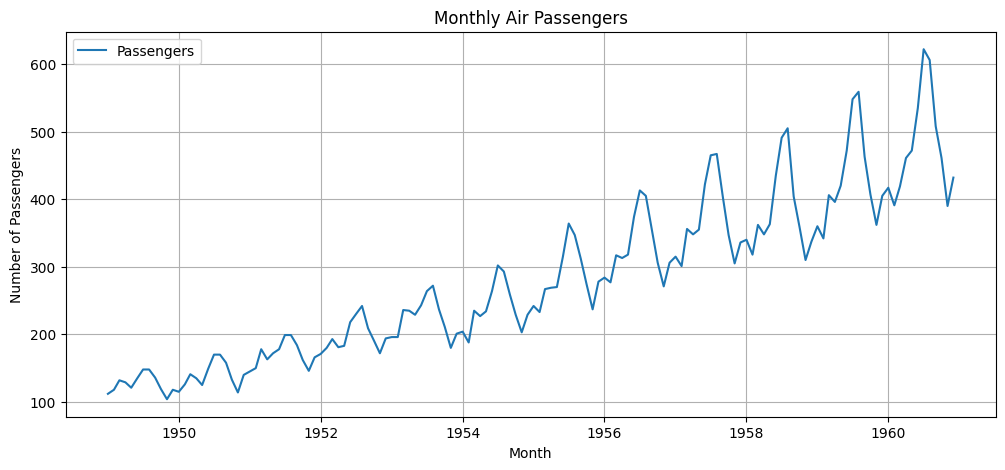

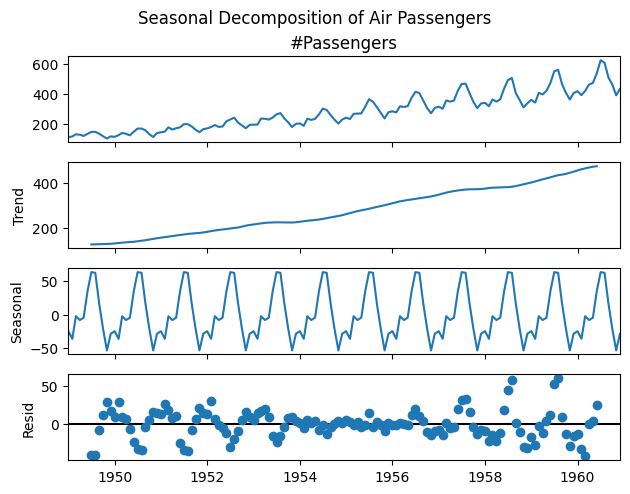

Training data size: 115
Testing data size: 29


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


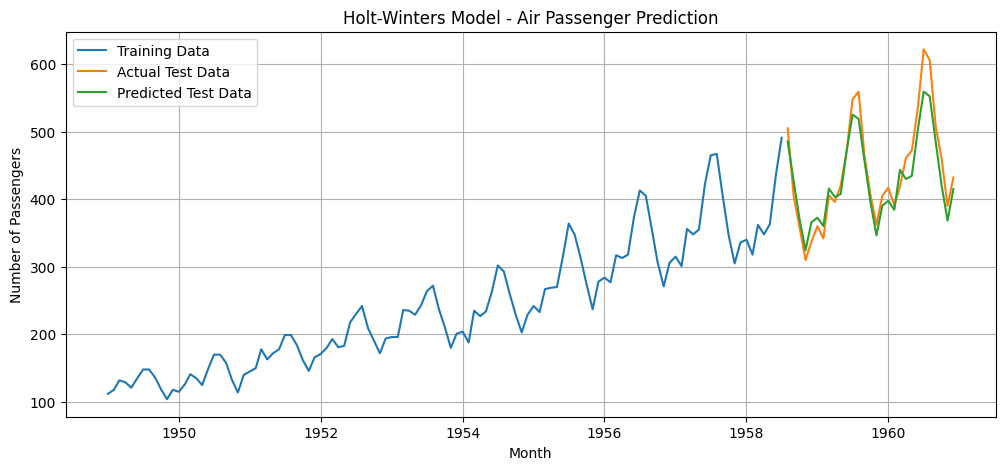

MAE: 21.962008308170425
RMSE: 26.041879997711003


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


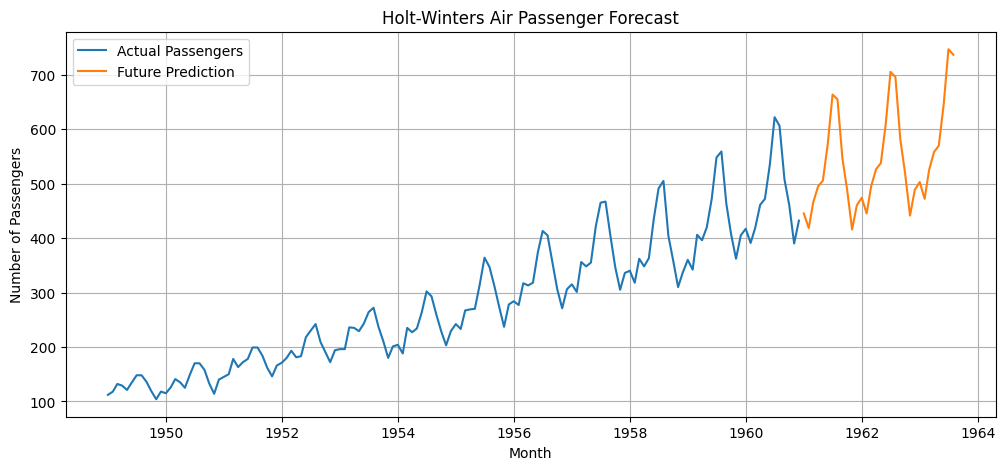


Future Passenger Predictions:
            Predicted_Passengers
1961-01-01            445.242404
1961-02-01            418.225356
1961-03-01            465.309718
1961-04-01            494.951214
1961-05-01            505.475856
1961-06-01            573.312593
1961-07-01            663.596298
1961-08-01            654.903946
1961-09-01            546.760961
1961-10-01            488.446893
1961-11-01            415.723600
1961-12-01            460.377975
1962-01-01            474.071220
1962-02-01            445.159526
1962-03-01            495.116209
1962-04-01            526.488112
1962-05-01            537.513243
1962-06-01            609.458604
1962-07-01            705.215816
1962-08-01            695.764737
1962-09-01            580.698041
1962-10-01            518.608449
1962-11-01            441.263077
1962-12-01            488.516684
1963-01-01            502.900035
1963-02-01            472.093697
1963-03-01            524.922700
1963-04-01            558.025010
1963-05-01  

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_absolute_error, mean_squared_error

data = pd.read_csv("/content/AirPassengers.csv")

print(data.head())
print(data.info())

data['Month'] = pd.to_datetime(
    data['Month'],
    format='%Y-%m'
)
data.set_index('Month', inplace=True)
data.sort_index(inplace=True)

print(data.head())
data_monthly = data['#Passengers'].dropna()

print("\nMonthly Passenger Data:")
print(data_monthly.head())

print("\nNumber of available observations:")
print(len(data_monthly))

plt.figure(figsize=(12, 5))

plt.plot(
    data_monthly,
    label='Passengers'
)

plt.title('Monthly Air Passengers')
plt.xlabel('Month')
plt.ylabel('Number of Passengers')
plt.legend()
plt.grid()

plt.show()


# ---------------------------------------------------
# SEASONAL DECOMPOSITION
# ---------------------------------------------------

decomposition = seasonal_decompose(
    data_monthly,
    model='additive',
    period=12
)

decomposition.plot()

plt.suptitle(
    "Seasonal Decomposition of Air Passengers",
    y=1.02
)

plt.show()


# ---------------------------------------------------
# SPLIT TRAIN AND TEST DATA
# ---------------------------------------------------

train_size = int(len(data_monthly) * 0.8)

train_data = data_monthly.iloc[:train_size]
test_data = data_monthly.iloc[train_size:]

print("Training data size:", len(train_data))
print("Testing data size:", len(test_data))


# ---------------------------------------------------
# CREATE HOLT-WINTERS MODEL
# ---------------------------------------------------

model = ExponentialSmoothing(
    train_data,
    trend='add',
    seasonal='mul',
    seasonal_periods=12
).fit()


# ---------------------------------------------------
# PREDICT TEST DATA
# ---------------------------------------------------

test_predictions = model.forecast(
    steps=len(test_data)
)


# ---------------------------------------------------
# VISUAL EVALUATION
# ---------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    train_data,
    label='Training Data'
)

plt.plot(
    test_data,
    label='Actual Test Data'
)

plt.plot(
    test_predictions,
    label='Predicted Test Data'
)

plt.title('Holt-Winters Model - Air Passenger Prediction')
plt.xlabel('Month')
plt.ylabel('Number of Passengers')

plt.legend()
plt.grid()

plt.show()


# ---------------------------------------------------
# MODEL PERFORMANCE METRICS
# ---------------------------------------------------

mae = mean_absolute_error(
    test_data,
    test_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        test_data,
        test_predictions
    )
)

print("MAE:", mae)
print("RMSE:", rmse)


# ---------------------------------------------------
# CREATE FINAL MODEL USING ALL AVAILABLE DATA
# ---------------------------------------------------

final_model = ExponentialSmoothing(
    data_monthly,
    trend='add',
    seasonal='mul',
    seasonal_periods=12
).fit()


# ---------------------------------------------------
# PREDICT FUTURE DATA
# ---------------------------------------------------

future_steps = 32

final_predictions = final_model.forecast(
    steps=future_steps
)


# ---------------------------------------------------
# PLOT FINAL PREDICTION
# ---------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    data_monthly,
    label='Actual Passengers'
)

plt.plot(
    final_predictions,
    label='Future Prediction'
)

plt.title('Holt-Winters Air Passenger Forecast')
plt.xlabel('Month')
plt.ylabel('Number of Passengers')

plt.legend()
plt.grid()

plt.show()


# ---------------------------------------------------
# DISPLAY FUTURE PREDICTIONS
# ---------------------------------------------------

future_forecast = pd.DataFrame({
    'Predicted_Passengers': final_predictions
})

print("\nFuture Passenger Predictions:")
print(future_forecast)